# **Main Code**

**Importing necessary libraries**

In [47]:
pip install matplotlib

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 7.8 MB 1.1 MB/s eta 0:00:01
     |████████████████████████████████| 249 kB 1.5 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 3.1 MB/s eta 0:00:01
     |████████████████████████████████| 2.8 MB 2.0 MB/s eta 0:00:01
     |████████████████████████████████| 107 kB 1.9 MB/s eta 0:00:01
     |████████████████████████████████| 3.1 MB 1.7 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
#from statsmodels.tsa.regime_switching.markov_switching import MarkovSwitching

**Dataset utilised in paper: to check results**

In [ ]:
#data_path = "/Users/utente/Desktop/Thesis/Thesis/src/data.xlsx"
#data = pd.read_excel(data_path, header=None)

**Read datasets**

In [8]:
pip install openpyxl

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 250 kB 941 kB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [9]:
file_path = "/Users/utente/Desktop/Thesis/Thesis/src/Thesis_Dataset.xlsx"
dataset = pd.read_excel(file_path)

rf_path = "/Users/utente/Desktop/Thesis/Thesis/src/Rf.xlsx"
rf = pd.read_excel(rf_path)

**Filter datasets to include data from July 1969 onward**

In [10]:
# Filter the dataset for all rows where the Date is greater than or equal to July 1969
dataset = dataset[dataset['Date'] >= '1969-07']
rf = rf[rf['Date'] >= '1969-07']
rf = rf.drop(rf.index[-1]) #exclude last observation to align the datasets
rf = rf.iloc[:, [0, -1]] #keep risk-free rate column as it is the information we are interested in
print(dataset.shape)
print(rf.shape)

(663, 50)
(663, 2)


Missing data are indicated by -99.99 or -999.

Check presence in our data.

In [11]:
# Identify missing data values (-99.99 and -999) in the dataset
missing_data_counts = (dataset == -99.99).sum() + (dataset == -999).sum()

# Display columns with missing data counts
missing_data_present = missing_data_counts[missing_data_counts > 0]

# If you want to check the total number of such missing values in the dataset:
total_missing_data = missing_data_counts.sum()
print(f"\nTotal missing data points in the dataset: {total_missing_data}")


Total missing data points in the dataset: 0


#### **Merge Datasets and obtain returns in excess of the risk-free rate**

In [12]:
# 1. Merge on the 'Date' column
df = pd.merge(dataset, rf, on='Date', how='inner')

# 2. Identify all industry columns (49 columns).
#    We'll treat every column except 'Date' and 'RF' as an industry column.
industry_cols = [col for col in df.columns if col not in ['Date', 'RF']]

# 3. Subtract the risk-free rate from each industry column
for col in industry_cols:
    df[col] = df[col] - df['RF']

# 4. Drop RF column
df.drop(columns='RF', inplace=True)    

# 5. The final DataFrame 'merged_df' now has:
#    - Date
#    - 49 columns with monthly EXCESS returns
df.head()


,Date,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,...,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
0,1969-07,-8.85,-7.45,-4.06,-2.63,-5.27,-8.40,-10.68,-11.60,-3.96,...,-3.68,-13.03,-10.62,-8.72,-10.46,-7.13,-10.71,-13.27,-9.58,-15.17
1,1969-08,3.73,4.02,4.94,6.13,3.49,5.92,11.06,9.29,4.27,...,5.58,5.09,5.88,7.71,8.48,12.26,8.30,14.56,8.39,7.88
2,1969-09,0.97,-1.20,4.66,-1.53,3.50,1.51,-0.05,-1.23,-1.14,...,0.61,-2.18,-0.41,-1.37,-1.97,-3.56,6.46,-4.41,-3.16,-7.29
3,1969-10,16.35,7.37,6.24,11.04,11.82,5.68,12.97,6.99,5.81,...,2.90,4.29,10.65,5.65,8.43,10.11,5.11,3.94,9.71,3.10
4,1969-11,-2.39,-1.18,-5.43,-3.35,0.09,-8.85,-3.79,-4.49,-2.94,...,-2.50,-8.43,-7.35,-4.60,-2.42,-9.51,-5.42,-6.75,-6.43,-2.77


#### **Markov Switching Factor Model**

In [71]:
class MarkovSwitchingFactorModel:
    """
    Two-state Markov switching factor model.
    """
    
    def __init__(self, 
                 N: int, 
                 r_1: int, 
                 r_2: int, 
                 P: np.ndarray,
                 factor_dynamics="AR1",
                 factor_params_1=None,
                 factor_params_2=None):
        
        self.N = N
        self.r_1 = r_1
        self.r_2 = r_2

        assert P.shape == (2,2), "Transition matrix must be 2x2."
        assert np.allclose(P.sum(axis=1), 1.0), "Rows of P must sum to 1."
        self.P = P

        self.factor_dynamics = factor_dynamics
        self.factor_params_1 = factor_params_1 if factor_params_1 is not None else {}
        self.factor_params_2 = factor_params_2 if factor_params_2 is not None else {}

        # Parameters to be estimated
        self.Lambda_1 = None
        self.Lambda_2 = None
        self.Sigma_e1 = None
        self.Sigma_e2 = None
        self.Chol_e1 = None
        self.Chol_e2 = None

    def fit(self, X: np.ndarray, max_iter=100, tol=1e-5):
        # Placeholder for fitting the model to real data
        # Here you will implement:
        # - State inference (forward-backward)
        # - Factor estimation (Kalman filter/PCA)
        # - Parameter updates (EM steps)
        
        # Ensure data is N x T
        if X.shape[0] != self.N:
            if X.shape[1] == self.N:
                X = X.T
            else:
                raise ValueError("Data dimensions do not match N.")
        
        # Initialize parameters if needed
        if self.Lambda_1 is None:
            self.Lambda_1 = np.random.randn(self.N, self.r_1) * 0.01
        if self.Lambda_2 is None:
            self.Lambda_2 = np.random.randn(self.N, self.r_2) * 0.01
        if self.Sigma_e1 is None:
            self.Sigma_e1 = np.eye(self.N)
        if self.Sigma_e2 is None:
            self.Sigma_e2 = np.eye(self.N)
        
        self.Chol_e1 = np.linalg.cholesky(self.Sigma_e1)
        self.Chol_e2 = np.linalg.cholesky(self.Sigma_e2)
        
        # Stub: EM iteration
        for iteration in range(max_iter):
            # E-step: Infer states and factors (not implemented)
            # M-step: Update parameters (not implemented)
            
            # Check for convergence (not implemented)
            pass

    def simulate_states(self, T: int, s0: int = 1):
        states = np.zeros(T, dtype=int)
        states[0] = s0
        for t in range(1, T):
            current_state = states[t-1] - 1
            states[t] = np.random.choice([1, 2], p=self.P[current_state,:])
        return states

    def simulate_factors(self, T: int, states: np.ndarray):
        f_1t = np.full((self.r_1, T), np.nan)
        f_2t = np.full((self.r_2, T), np.nan)

        phi_1 = self.factor_params_1.get("phi", 0.0) if self.factor_dynamics == "AR1" else 0.0
        phi_2 = self.factor_params_2.get("phi", 0.0) if self.factor_dynamics == "AR1" else 0.0

        if self.r_1 > 0:
            f_1_current = np.zeros(self.r_1)
        if self.r_2 > 0:
            f_2_current = np.zeros(self.r_2)

        for t in range(T):
            st = states[t]
            if st == 1 and self.r_1 > 0:
                eps = np.random.randn(self.r_1)
                f_1_current = phi_1 * f_1_current + eps
                f_1t[:, t] = f_1_current
            elif st == 2 and self.r_2 > 0:
                eps = np.random.randn(self.r_2)
                f_2_current = phi_2 * f_2_current + eps
                f_2t[:, t] = f_2_current
        return f_1t, f_2t

    def simulate_data(self, T: int, s0: int = 1):
        if self.Lambda_1 is None or self.Lambda_2 is None:
            self.Lambda_1 = np.random.randn(self.N, self.r_1) * 0.1
            self.Lambda_2 = np.random.randn(self.N, self.r_2) * 0.1
        if self.Sigma_e1 is None or self.Sigma_e2 is None:
            self.Sigma_e1 = np.eye(self.N)
            self.Sigma_e2 = np.eye(self.N)
        if self.Chol_e1 is None:
            self.Chol_e1 = np.linalg.cholesky(self.Sigma_e1)
        if self.Chol_e2 is None:
            self.Chol_e2 = np.linalg.cholesky(self.Sigma_e2)

        states = self.simulate_states(T, s0=s0)
        f_1t, f_2t = self.simulate_factors(T, states)
        
        x = np.zeros((self.N, T))
        for t in range(T):
            st = states[t]
            nu_t = np.random.randn(self.N)
            if st == 1:
                if self.r_1 > 0:
                    x[:, t] = self.Lambda_1 @ f_1t[:, t] + self.Chol_e1 @ nu_t
                else:
                    x[:, t] = self.Chol_e1 @ nu_t
            else:
                if self.r_2 > 0:
                    x[:, t] = self.Lambda_2 @ f_2t[:, t] + self.Chol_e2 @ nu_t
                else:
                    x[:, t] = self.Chol_e2 @ nu_t
        return x, states, f_1t, f_2t


#### **Demeaning of returns**

Centering the data will be important for later steps, thus, we proceed with demeaning the returns.

This operation, effectively, makes it so that our unconditional returns are equal to 0.

In [13]:
# Step 1: Separate the 'Date' column
dates = df['Date']
returns_data = df.loc[:, df.columns != 'Date']

# Step 2: Compute the mean of each portfolio
portfolio_means = returns_data.mean(axis=0)

# Step 3: Demean the returns
demeaned_returns = returns_data.subtract(portfolio_means, axis=1)

# Step 4: Verify the unconditional mean is zero
demeaned_means = demeaned_returns.mean(axis=0)
# Check that the absolute values are close to zero
print((demeaned_means.abs() < 1e-12).all())  # Should return True

# Step 5: Save back the returns dataset as "VWExcessRet"
VWExcessRet = demeaned_returns

VWExcessRet.columns = range(VWExcessRet.shape[1])

True


In [293]:
# Save transformed dataset
VWExcessRet.to_excel('VWExcessRet.xlsx', index=False)

##### **Volatily Investigation**

In [ ]:
# Compute the standard deviation (volatility) of each column
vols = VWExcessRet.std()  

# Print or inspect the numeric results
print("Standard Deviation (Volatility) of each column:")
print(vols)

Standard Deviation (Volatility) of each column:
0      6.453325
1      4.452403
2      6.392082
3      5.157555
4      6.197449
5      7.394702
6      7.954004
7      6.114101
8      4.676922
9      6.754663
10     8.039283
11     5.366491
12     4.979594
13     5.809623
14     6.098009
15     7.801197
16     6.493954
17     7.466165
18     8.070390
19     7.952170
20     6.495753
21     6.585972
22     8.131374
23     6.890748
24     7.376672
25     6.486294
26    10.757446
27     7.689091
28    11.176463
29     6.293134
30     4.149053
31     4.808080
32     6.689767
33     5.776886
34     7.166695
35    10.256347
36     7.575685
37     6.910807
38     5.580358
39     5.730175
40     6.032523
41     5.540470
42     5.571942
43     6.081433
44     6.231412
45     5.490230
46     7.743098
47     6.358171
48     6.592466
dtype: float64


**From these results, we can see that the standard deviations range from roughly 4.15 up to 11.18 (and everything in between). In other words, some industry portfolios exhibit more than twice the volatility of others.**

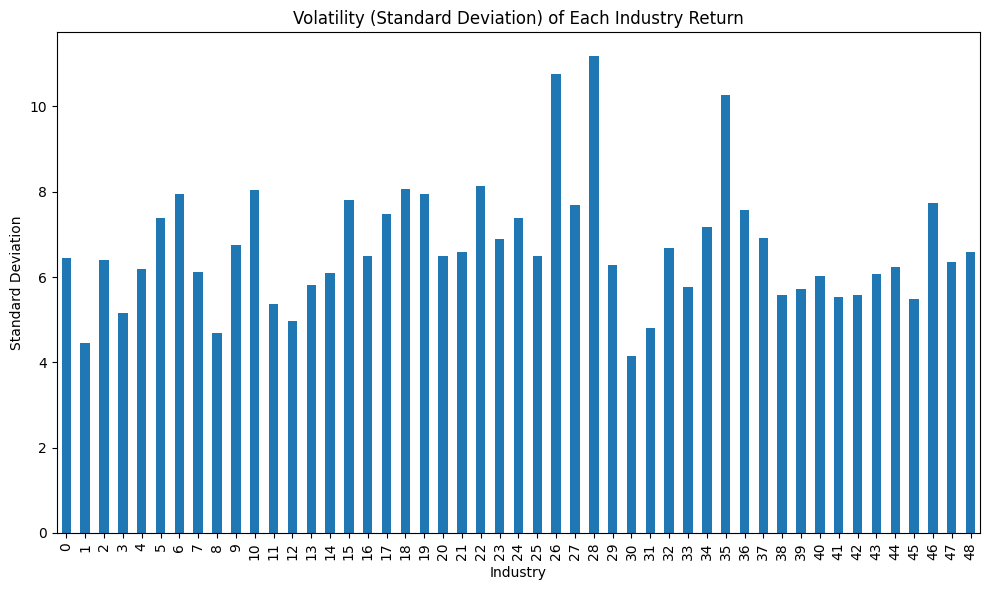

In [49]:
# Plot the volatilities as a bar chart
plt.figure(figsize=(10, 6))
vols.plot(kind='bar')
plt.title("Volatility (Standard Deviation) of Each Industry Return")
plt.ylabel("Standard Deviation")
plt.xlabel("Industry")
plt.tight_layout()
plt.show()

#### **Implement estimators to obtain the optimal number of latent factors**

##### **Eigenvalue Ratio estimator**

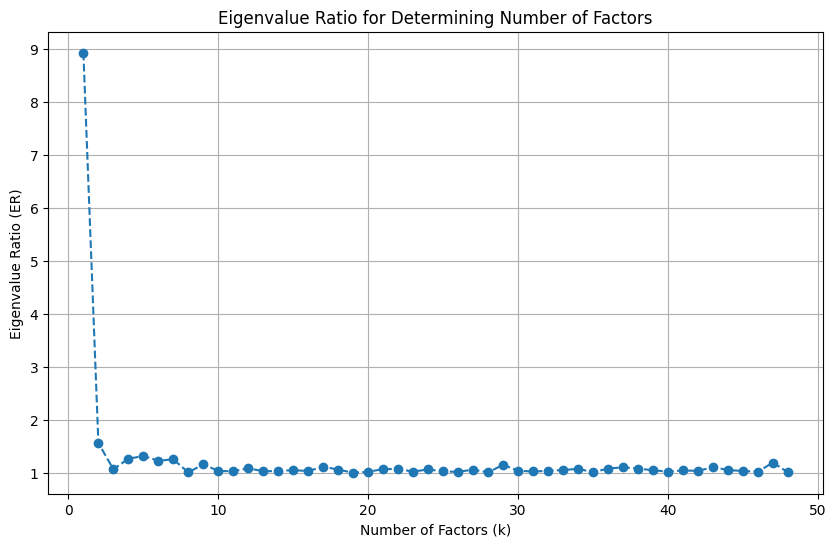

Optimal number of factors: 1


In [122]:
# Step 1: Compute the covariance matrix of the dataset
cov_matrix= np.cov(VWExcessRet, rowvar=False)

# Step 2: Compute the eigenvalues of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

# Step 3: Sort eigenvalues in descending order
eigenvalues = np.sort(eigenvalues)[::-1]

# Step 4: Calculate the Eigenvalue Ratio (ER) for each k
er_ratios = [eigenvalues[i] / eigenvalues[i + 1] for i in range(len(eigenvalues) - 1)]

# Step 5: Find the optimal number of factors by finding the maximum ratio
optimal_num_factors = np.argmax(er_ratios) + 1

# Step 6: Plot the eigenvalue ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(er_ratios) + 1), er_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Eigenvalue Ratio (ER)')
plt.title('Eigenvalue Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors: {optimal_num_factors}")

##### **Growth Ratio estimator**

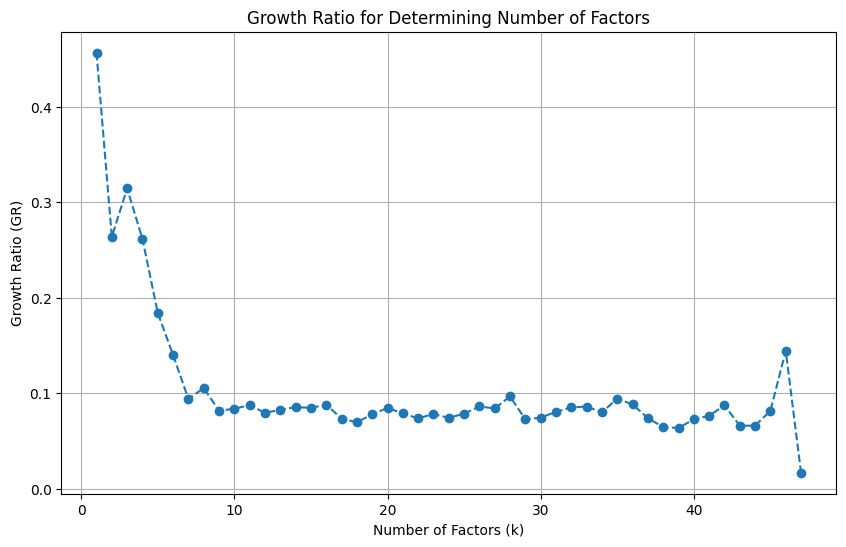

Optimal number of factors (Growth Ratio): 1


In [123]:
# Step 1: Calculate the Growth Ratio (GR) for each k
V = [np.sum(eigenvalues[i+1:]**2) / (len(eigenvalues) - (i + 1)) for i in range(len(eigenvalues) - 1)]
gr_ratios = [np.log(V[k]) - np.log(V[k + 1]) for k in range(len(V) - 1)]

# Step 2: Find the optimal number of factors by finding the maximum growth ratio
optimal_num_factors_gr = np.argmax(gr_ratios) + 1

# Step 3: Plot the growth ratios for visualization
plt.figure(figsize=(10, 6))
plt.plot(range(1, len(gr_ratios) + 1), gr_ratios, marker='o', linestyle='--')
plt.xlabel('Number of Factors (k)')
plt.ylabel('Growth Ratio (GR)')
plt.title('Growth Ratio for Determining Number of Factors')
plt.grid(True)
plt.show()

print(f"Optimal number of factors (Growth Ratio): {optimal_num_factors_gr}")

#### **Number of factors**

In [263]:
# maximum number of factors
rmax = 10

# Preallocate ER and GR
ER = np.zeros((rmax, 1))
GR = np.zeros((rmax, 1))

# Get covariance matrix 
Sigma = np.cov(VWExcessRet, rowvar=False)

# Get eigenvalues of covariance matrix
vals, _ = np.linalg.eigh(Sigma)

# Sort eigenvalues in descending order
vals_sorted = np.sort(vals)[::-1]

# Take top (rmax+1) eigenvalues
DAH = vals_sorted[:rmax+1]

# Compute ER and GR
for j in range(rmax):
    ER[j, 0] = DAH[j] / DAH[j+1]
    GR[j, 0] = np.log(1 + DAH[j]) / np.log(1 + DAH[j+1])

# Find index of maximum GR
max_val = np.max(GR[1:, 0])  # ignoring first row, i.e. index 0
indices = np.where(GR[:, 0] == max_val)[0]  # returns 0-based indices
r = indices[0] + 1 # r = 2

r = 2

##### **Estimation of factors and loadings**

In [264]:
# From previous estimation, we know that the number of factors is 2
r = 2

# Get top eigenvalues and eigenvectors of covariance matrix calculated before
vals, vecs = np.linalg.eigh(Sigma)

# Sort eigenvalues (and corresponding vectors) in descending order
idx = np.argsort(vals)[::-1]
vals = vals[idx]
vecs = vecs[:, idx]

# Extract the top-r eigenvalues/vectors
vals_r = vals[:r]                 
vecs_r = vecs[:, :r] 

# Calculation of factor scores ghat
D_inv_sqrt = np.diag(1.0 / np.sqrt(vals_r))
ghat = (D_inv_sqrt @ vecs_r.T @ VWExcessRet.T).T

# Calculation of loadings Ahat
D_sqrt = np.diag(np.sqrt(vals_r)) 
Ahat = vecs_r @ D_sqrt  

# Reconstructed data
chihat = (Ahat @ ghat.T).T

# Reconstructed data using only 2 factors
chihat1 = (vecs_r @ vecs_r.T @ VWExcessRet.T).T

# Calculation of residuals
ehat = VWExcessRet-chihat

## **EM algorithm**

#### **Initialization of EM parameters**

In [265]:
# EM parameters
kmax = 100
thresh = 1e-6
eps = [0.49, 0.1] 
min_eta = 1e-50

#### **Pre-allocate parameters**

In [399]:
T, N = VWExcessRet.shape

# Create arrays of zeros of correct dimensions to be filled in the estimation phase

Phat       = np.zeros((2, 2, kmax+1))
rhohat     = np.zeros((2*2, kmax+1))   
Bhat       = np.zeros((N, r, 2, kmax+1))
Sigmaehat  = np.zeros((N, N, 2, kmax+1))
etahat     = np.zeros((T, 2, kmax+1))
llik       = np.zeros((kmax+1, 1))    

xit1       = np.zeros((T, 2, kmax+1))
xitt       = np.zeros((T, 2, kmax+1))
xitT       = np.zeros((T, 2, kmax+1))
xitT2      = np.zeros((T, 2*2, kmax+1))  

fhat       = np.zeros((T, r))

temp1      = np.zeros((T, N, 2))
temp2      = np.zeros((T, 2, 2))
temp3      = np.zeros((T,N))

xibar      = np.zeros((2,2))

Define function to reshape an array into a column vector.

In [365]:
def ML_vec(X):
    
    m, n = X.shape
    x = X.reshape(m*n, order='F')
    
    return x

In [401]:
# Initialize parameters

# Assign Bhat
Bhat[:, :, 0, 0] = Ahat
Bhat[:, :, 1, 0] = Ahat

# Assign Sigmaehat
Sigma_e = np.diag(np.diag(np.cov(ehat, rowvar=False)))  # (N,N)
Sigmaehat[:, :, 0, 0] = Sigma_e
Sigmaehat[:, :, 1, 0] = Sigma_e

# Assign first Phat
Phat[:, :, 0] = np.array([
    [0.5 + eps[0],       1 - 0.5 - eps[0]],
    [1 - 0.5 - eps[1],   0.5 + eps[1]]
])

# Assign rhohat
rhohat[:, 0] = ML_vec(Phat[:, :, 0])

xi00 = np.array([1, 0])

In [402]:
# Ensure VWExcessRet is a NumPy array
x = VWExcessRet.to_numpy() if isinstance(VWExcessRet, pd.DataFrame) else VWExcessRet

print(type(x))        # Should print <class 'numpy.ndarray'>
print(x.shape)        # Confirm the dimensions are (T, N)

#ghat = ghat.to_numpy()
print(type(ghat))        # Should print <class 'numpy.ndarray'>
print(ghat.shape)        # Confirm the dimensions are (T, r)

<class 'numpy.ndarray'>
(663, 49)
<class 'numpy.ndarray'>
(663, 2)


In [405]:
# Initialize state
xit1[0, :, 0] = (Phat[:, :, 0].T @ xi00).T

Ec = np.eye(2)

for t in range(T):
    for j in range(2):
        etahat[t, j, 0] = (2 * np.pi) ** (-N / 2) * (np.linalg.det(Sigmaehat[:, :, j, 0])) ** (-1 / 2) * \
            np.exp(-((x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, 0], Bhat[:, :, 1, 0])).T) @ \
            np.linalg.inv(Sigmaehat[:, :, j, 0]) @ \
            (x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, 0], Bhat[:, :, 1, 0])).T).T) / 2)
        if etahat[t, j, 0] == 0:
            etahat[t, j, 0] = min_eta

for k in range(kmax):
    print(f'EM iteration {k}')
    llik[k, 0] = np.sum(np.log(etahat[:, 0, k] + etahat[:, 1, k]))
    print(f'--llik {llik[k, 0]}')

    # E-step
    # Hamilton filter
    for t in range(T):
        xitt[t, :, k] = (etahat[t, :, k] * xit1[t, :, k]) / (np.ones(2) @ (etahat[t, :, k] * xit1[t, :, k]))
        if t < T - 1:
            xit1[t + 1, :, k] = (Phat[:, :, k].T @ xitt[t, :, k]).T

    # Kim smoother
    xitT[T - 1, :, k] = xitt[T - 1, :, k]
    xitT[T - 2, :, k] = ((Phat[:, :, k] @ (xitt[T - 1, :, k] / xit1[T - 1, :, k]).T) * xitt[T - 2, :, k]).T

    revt = np.flipud(np.arange(T - 2))

    for t in range(T - 2):
        xitT[revt[t], :, k] = ((Phat[:, :, k] @ (xitT[revt[t] + 1, :, k] / xit1[revt[t] + 1, :, k]).T) * xitt[revt[t], :, k]).T

    for t in range(1, T):
        xitT2[t, :, k] = np.kron(xitT[t - 1, :, k], xitT[t, :, k])

    if k > 1 and abs(llik[k, 0] - llik[k - 1, 0]) / (0.5 * abs(llik[k, 0] + llik[k - 1, 0])) < thresh:
        kstar = k
        break

    # M-step
    # Estimate parameters
    for j in range(2):
         for t in range(T):
              temp1[t, :, :] = np.outer(x[t, :], ghat[t, :])
              temp2[t, :, :] = np.outer(ghat[t, :], ghat[t, :])

         # Now multiply with xitT[:, j, k] reshaped to (T,1,1)
         sum_temp1 = np.sum(temp1 * xitT[:, j, k, np.newaxis, np.newaxis], axis=0)
         sum_temp2 = np.sum(temp2 * xitT[:, j, k, np.newaxis, np.newaxis], axis=0)
    
         Bhat[:, :, j, k + 1] = sum_temp1 @ np.linalg.inv(sum_temp2)

         for t in range(T):
             temp3[t, :] = (x[t, :] - ghat[t, :] @ Bhat[:, :, j, k + 1].T) ** 2

         Sigmaehat[:, :, j, k + 1] = (np.diag(np.sum(temp3 * xitT[:, j, k, np.newaxis], axis=0)) / np.sum(xitT[:, j, k]))

    # rhohat calculation
    numerator = np.sum(xitT2[:, :, k], axis=0)
    temp = np.sum(xitT[1:T, :, k], axis=0).reshape(-1, 1)  # shape (2,1)
    denominator_2d = np.kron(np.ones((2, 1)), temp)        # shape (4,1)
    denominator = denominator_2d.ravel()                   # shape (4,)

    # Elementwise division => shape (4,)
    rhohat[:, k + 1] = numerator / denominator

    Phat[:, :, k + 1] = np.reshape(rhohat[:, k + 1], (2, 2))

    # New initialization of state
    xit1[0, :, k + 1] = np.mean(xitT[:, :, k], axis=0)

    for t in range(T):
        for j in range(2):
            etahat[t, j, k + 1] = (2 * np.pi) ** (-N / 2) * (np.linalg.det(Sigmaehat[:, :, j, k + 1])) ** (-1 / 2) * \
                np.exp(-((x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, k + 1], Bhat[:, :, 1, k + 1])).T) @ \
                np.linalg.inv(Sigmaehat[:, :, j, k + 1]) @ \
                (x[t, :] - np.kron(Ec[j, :], ghat[t, :]) @ np.hstack((Bhat[:, :, 0, k + 1], Bhat[:, :, 1, k + 1])).T).T) / 2)
            if etahat[t, j, k + 1] == 0:
                etahat[t, j, k + 1] = min_eta

if k == kmax:
    print('EM did not converge')
    kstar = kmax

xibar[0, :] = np.mean(xitT[:, :, kstar], axis=0)
xibar[1, :] = [(1 - Phat[1, 1, kstar]), (1 - Phat[0, 0, kstar])] / (2 - Phat[0, 0, kstar] - Phat[1, 1, kstar])

chihat0[:, :, 0] = Bhat[:, :, 0, kstar] * (ghat * np.round(xitT[:, 0, kstar]))[:, np.newaxis]
chihat0[:, :, 1] = Bhat[:, :, 1, kstar] @ (ghat * np.round(xitT[:, 1, kstar]))[:, np.newaxis]

fhat[:, 0] = xitT[:, 0, kstar] * x @ Bhat[:, 0, 0, kstar] / (Bhat[:, 0, 0, kstar].T @ Bhat[:, 0, 0, kstar])
fhat[:, 1] = xitT[:, 1, kstar] * x @ Bhat[:, 1, 1, kstar] / (Bhat[:, 1, 1, kstar].T @ Bhat[:, 1, 1, kstar])

ftilde[:, 0] = xitT[:, 0, kstar] * x @ Bhat[:, 0, 1, kstar] / (Bhat[:, 0, 1, kstar].T @ Bhat[:, 0, 1, kstar])
ftilde[:, 1] = xitT[:, 1, kstar] * x @ Bhat[:, 1, 0, kstar] / (Bhat[:, 1, 0, kstar].T @ Bhat[:, 1, 0, kstar])




EM iteration 0
--llik -89756.87740949457
EM iteration 1
--llik -89756.7935280115
EM iteration 2
--llik -89744.91780112244
EM iteration 3
--llik -89607.36390755765
EM iteration 4
--llik -88808.00606710107
EM iteration 5
--llik -88001.08157984461
EM iteration 6
--llik -87884.89089873387
EM iteration 7
--llik -87857.47478940945
EM iteration 8
--llik -87841.54635838307
EM iteration 9
--llik -87830.68366362143
EM iteration 10
--llik -87823.93465494289
EM iteration 11
--llik -87820.33030766786
EM iteration 12
--llik -87817.97820738281
EM iteration 13
--llik -87816.11307257507
EM iteration 14
--llik -87813.84207492787
EM iteration 15
--llik -87810.81703685556
EM iteration 16
--llik -87809.19873287069
EM iteration 17
--llik -87808.16045463982
EM iteration 18
--llik -87807.30731991853
EM iteration 19
--llik -87806.51102221955
EM iteration 20
--llik -87805.74173350444
EM iteration 21
--llik -87805.00655110346
EM iteration 22
--llik -87804.31543717548
EM iteration 23
--llik -87803.6767589048
EM i

ValueError: operands could not be broadcast together with shapes (663,2) (663,) 

## **Neural Networks** 

### **Autoencoders for factor extraction**

In [1]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 239.4 MB 103 kB/s eta 0:00:01     |████████████████████████████▌   | 213.3 MB 3.0 MB/s eta 0:00:09
     |████████████████████████████████| 1.3 MB 1.4 MB/s eta 0:00:01
     |████████████████████████████████| 5.5 MB 2.7 MB/s eta 0:00:01
     |████████████████████████████████| 396 kB 28.7 MB/s eta 0:00:01
     |████████████████████████████████| 71 kB 1.3 MB/s  eta 0:00:01
     |████████████████████████████████| 5.3 MB 1.4 MB/s eta 0:00:01
     |████████████████████████████████| 64 kB 9.4 MB/s  eta 0:00:01
     |████████████████████████████████| 417 kB 933 kB/s eta 0:00:01
     |████████████████████████████████| 2.9 MB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 11.1 MB 2.8 MB/s eta 0:00:01
     |████████████████████████████████| 57 kB 12.6 MB/s eta 0:00:01
     |████████████████████████████████| 3.5 MB 24.5 MB/s eta 0:00:01
     |██████████████████████████

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.preprocessing import StandardScaler

In [36]:
# Scale each column to unit variance:
scaler = StandardScaler(with_mean=False)  # <-- no mean subtraction, only std
data_scaled = scaler.fit_transform(VWExcessRet)

In [54]:
# Calculate the variance of each column in data_scaled
col_variances = data_scaled.var(axis=0, ddof=0)  # ddof=0 for population variance
print("Variances of each column in the scaled data:\n", col_variances)

Variances of each column in the scaled data:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1.]


In [37]:
# -------------------------------------------------
# Define the autoencoder
# -------------------------------------------------
input_dim = 49
latent_dim = 2  

inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(32, activation='relu')(inputs)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)

x = layers.Dense(16, activation='relu')(latent)
x = layers.Dense(32, activation='relu')(x)
outputs = layers.Dense(input_dim, activation='linear')(x)

autoencoder = keras.Model(inputs, outputs, name="autoencoder")
encoder = keras.Model(inputs, latent, name="encoder")

# -------------------------------------------------
# Compile & train
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

history = autoencoder.fit(
    data_scaled, data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,
    verbose=1
)

# -------------------------------------------------
# Extract the 2-factor representation
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)
print("Shape of extracted factors:", factors_2d.shape)

# factors_2d is now (663, 2)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 1.0594 - val_loss: 1.2080
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9654 - val_loss: 1.0448
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7399 - val_loss: 0.9100
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7006 - val_loss: 0.7370
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5883 - val_loss: 0.5694
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4714 - val_loss: 0.5297
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4246 - val_loss: 0.5188
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4194 - val_loss: 0.5162
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3924 - val_loss: 0.5148
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4065 - val_loss: 0.5105
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3926 - val_loss: 0.5114
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.

In [38]:
# ---------------------------------------------------------------------
# Reconstruct data and check reconstruction performance
# ---------------------------------------------------------------------
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Reconstruction MSE:", mse)

21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step
Reconstruction MSE: 0.351778822568948


#### **Increase Model Capacity (More Hidden Units)** 

**By adding more (or wider) hidden layers, we give the network more representational power to learn complex patterns.**

In [ ]:
input_dim = 49
latent_dim = 2  

# -------------------------------
# Encoder
# -------------------------------
encoder_inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(64, activation='relu')(encoder_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -------------------------------
# Decoder
# -------------------------------
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16, activation='relu')(decoder_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
decoder_outputs = layers.Dense(input_dim, activation='linear')(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -------------------------------
# Autoencoder = Encoder + Decoder
# -------------------------------
autoencoder_inputs = keras.Input(shape=(input_dim,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)

autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------
# Train
# -------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, # monitor validation loss to ensure we are not overfitting
    verbose=1
)

# -------------------------------
# Extract factors & evaluate
# -------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
mse = np.mean((data_scaled - autoencoder.predict(data_scaled))**2)
print("Reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.9611 - val_loss: 1.1122
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8270 - val_loss: 0.7687
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.5395 - val_loss: 0.5362
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4317 - val_loss: 0.5160
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3923 - val_loss: 0.5138
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4048 - val_loss: 0.5096
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3951 - val_loss: 0.5072
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3989 - val_loss: 0.5093
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4015 - val_loss: 0.5026
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3977 - val_loss: 0.5044
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3805 - val_loss: 0.5004
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**Below we implement an even deeper autoencoder architecture that uses layer widths of 128, 64, 32, and 16 in the encoder (and symmetrically in the decoder).**

In [ ]:
input_dim = 49
latent_dim = 2  

# -------------------------------
# Encoder
# -------------------------------
encoder_inputs = keras.Input(shape=(input_dim,))
x = layers.Dense(128, activation='relu')(encoder_inputs)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(16, activation='relu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -------------------------------
# Decoder
# -------------------------------
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16, activation='relu')(decoder_inputs)
x = layers.Dense(32, activation='relu')(x)
x = layers.Dense(64, activation='relu')(x)
x = layers.Dense(128, activation='relu')(x)
decoder_outputs = layers.Dense(input_dim, activation='linear')(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -------------------------------
# Autoencoder = Encoder + Decoder
# -------------------------------
autoencoder_inputs = keras.Input(shape=(input_dim,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)

autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile & set up callbacks
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# EarlyStopping callback to prevent overfitting
#early_stopping = keras.callbacks.EarlyStopping(
 #   monitor='val_loss',
  #  patience=10,             # stops if val_loss doesn’t improve for 10 epochs
   # restore_best_weights=True
#)

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,  
    #callbacks=[early_stopping],
    verbose=1
)

# -------------------------------------------------
# Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Final reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.9130 - val_loss: 1.0056
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7461 - val_loss: 0.6075
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4578 - val_loss: 0.5216
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4001 - val_loss: 0.5150
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4077 - val_loss: 0.5146
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.4018 - val_loss: 0.5134
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4062 - val_loss: 0.5118
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3969 - val_loss: 0.5140
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.3894 - val_loss: 0.5119
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3912 - val_loss: 0.5135
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3834 - val_loss: 0.5109
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**We can see that the autoencoder architecture that uses increasing layer widths always yields slightly better results. Let's try with different activation functions.**

#### **Alternative Activation Functions**

**Until now, we have utlised the most common method called ReLu (Rectified Linear Unit). We will now try different options.**

##### **Leaky ReLu**

**Variation of ReLu that allows a small, non-zero gradient when $x < 0$.**

In [39]:
T, N = VWExcessRet.shape

# -------------------------------------------------
#  Define the autoencoder architecture using LeakyReLU
# -------------------------------------------------
alpha = 0.01  # LeakyReLU negative slope
latent_dim = 2  # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))
x = layers.Dense(128)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(16)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

latent = layers.Dense(latent_dim, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(128)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

decoder_outputs = layers.Dense(N)(x)  # linear output
decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled, 
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, 
    verbose=1
)

# -------------------------------------------------
# Evaluate
# -------------------------------------------------
# Extract the 2D latent factors
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)

# Check reconstruction MSE on the full dataset
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Final reconstruction MSE:", mse)

Epoch 1/100


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 17ms/step - loss: 0.8868 - val_loss: 0.8596
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.6071 - val_loss: 0.5783
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4512 - val_loss: 0.5137
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3944 - val_loss: 0.5119
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4177 - val_loss: 0.5121
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4085 - val_loss: 0.5090
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3980 - val_loss: 0.5091
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3944 - val_loss: 0.5096
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4062 - val_loss: 0.4994
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3894 - val_loss: 0.4981
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3897 - val_loss: 0.4971
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3539 - val_l

##### **ELU (Exponential Linear Unit)**

**Helps the mean activations closer to zero and can be more robust.**

In [29]:
# -------------------------------------------------
# Define the autoencoder architecture using ELU activation
# -------------------------------------------------
# Keras 'elu' activation defaults alpha=1.0
latent_dim = 2  # number of latent factors

# --- Encoder ---
encoder_inputs = keras.Input(shape=(N,))
x = layers.Dense(128, activation='elu')(encoder_inputs)
x = layers.Dense(64, activation='elu')(x)
x = layers.Dense(32, activation='elu')(x)
x = layers.Dense(16, activation='elu')(x)
latent = layers.Dense(latent_dim, activation='linear', name='latent_layer')(x)
encoder = keras.Model(encoder_inputs, latent, name="encoder")

# --- Decoder ---
decoder_inputs = keras.Input(shape=(latent_dim,))
x = layers.Dense(16, activation='elu')(decoder_inputs)
x = layers.Dense(32, activation='elu')(x)
x = layers.Dense(64, activation='elu')(x)
x = layers.Dense(128, activation='elu')(x)
decoder_outputs = layers.Dense(N, activation='linear')(x)
decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# --- Combine into Autoencoder ---
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# 3. Compile & EarlyStopping
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# 4. Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,  
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
# Extract the 2D latent factors
factors_2d = encoder.predict(data_scaled)  # shape (663, 2)

# Check reconstruction MSE
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)
print("Final reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.8702 - val_loss: 0.6305
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4824 - val_loss: 0.5572
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4576 - val_loss: 0.5077
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4097 - val_loss: 0.5118
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4009 - val_loss: 0.4938
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3832 - val_loss: 0.4884
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3830 - val_loss: 0.4883
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3809 - val_loss: 0.4858
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3614 - val_loss: 0.4847
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3533 - val_loss: 0.4817
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3528 - val_loss: 0.4866
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**We can see that the activation function Leaky ReLu has the better reconstructed MSE**

#### **Other strategies to improve performance**

##### **Regularization**

**Let's implement and autoencoder that utlises layers width of 128, 64, 32, 16 and LeakyReLU activation function and that includes L2 regularization (weight decay) in each layer. L2 regularization penalizes large weights in the network. The penalty is added to the loss function during training, encouraging smaller parameter values and helping to reduce overfitting.**

In [31]:
# -------------------------------------------------
# Define the autoencoder with LeakyReLU & L2 regularization
# -------------------------------------------------
alpha = 0.01  # slope for LeakyReLU when x < 0
l2_reg = keras.regularizers.l2(1e-5)  # L2 regularization weight
latent_dim = 2  # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))

x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Latent layer (linear activation by default):
latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Final reconstruction layer
decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, 
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)

print("Final reconstruction MSE:", mse)

Epoch 1/100


/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.8829 - val_loss: 0.8793
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6147 - val_loss: 0.5519
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4163 - val_loss: 0.5237
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3996 - val_loss: 0.5150
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4199 - val_loss: 0.5199
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4170 - val_loss: 0.5160
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3910 - val_loss: 0.5150
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4014 - val_loss: 0.5159
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4017 - val_loss: 0.5093
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4029 - val_loss: 0.5037
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3893 - val_loss: 0.4909
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3858 - val_l

##### **Dropout**

**Dropout randomly drops 20% of the neurons, helping to prevent overfitting.**

In [33]:
# -------------------------------------------------
# 2. Define the autoencoder architecture
#    with LeakyReLU, L2 regularization, and Dropout
# -------------------------------------------------
alpha = 0.01  # slope for LeakyReLU when x < 0
l2_reg = keras.regularizers.l2(1e-5)  # L2 weight regularization
drop_rate = 0.2  # 20% dropout
latent_dim = 2   # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))

x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

# Latent layer (linear activation by default)
latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)
x = layers.Dropout(drop_rate)(x)

# Final reconstruction layer
decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# 3. Compile & EarlyStopping
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# 4. Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1,  # 10% for validation
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
factors_2d = encoder.predict(data_scaled)  # shape = (663, 2)
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)

print("Final reconstruction MSE:", mse)
print("Latent factors shape:", factors_2d.shape)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 1.0385 - val_loss: 1.1872
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9749 - val_loss: 0.9274
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8673 - val_loss: 0.7839
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7034 - val_loss: 0.6985
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5936 - val_loss: 0.6210
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5519 - val_loss: 0.5746
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5683 - val_loss: 0.6334
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5107 - val_loss: 0.5692
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5004 - val_loss: 0.5926
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5087 - val_loss: 0.5653
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5149 - val_loss: 0.5872
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.

**We will settle for the autoencoder with layer widths of 128, 64, 32, 16, Leaky ReLU function and regularization.**

In [219]:
# -------------------------------------------------
# Define the autoencoder with LeakyReLU & L2 regularization
# -------------------------------------------------
alpha = 0.01  # slope for LeakyReLU when x < 0
l2_reg = keras.regularizers.l2(1e-5)  # L2 regularization weight
latent_dim = 2  # number of factors in the bottleneck

# -- Encoder --
encoder_inputs = keras.Input(shape=(N,))

x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Latent layer (linear activation by default):
latent = layers.Dense(latent_dim, kernel_regularizer=l2_reg, name='latent_layer')(x)

encoder = keras.Model(encoder_inputs, latent, name="encoder")

# -- Decoder --
decoder_inputs = keras.Input(shape=(latent_dim,))

x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
x = layers.LeakyReLU(alpha=alpha)(x)

# Final reconstruction layer
decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)

decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

# -- Combine into Autoencoder --
autoencoder_inputs = keras.Input(shape=(N,))
encoded = encoder(autoencoder_inputs)
decoded = decoder(encoded)
autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

# -------------------------------------------------
# Compile
# -------------------------------------------------
autoencoder.compile(optimizer='adam', loss='mse')

# -------------------------------------------------
# Train
# -------------------------------------------------
history = autoencoder.fit(
    data_scaled,
    data_scaled,
    epochs=100,
    batch_size=32,
    shuffle=True,
    validation_split=0.1, 
    verbose=1
)

# -------------------------------------------------
# 5. Evaluate
# -------------------------------------------------
factors = encoder.predict(data_scaled)  # shape = (663, 2) #factors_2d
reconstructions = autoencoder.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions)**2)

print("Final reconstruction MSE:", mse)

Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - loss: 0.8979 - val_loss: 0.9313
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6245 - val_loss: 0.6311
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4645 - val_loss: 0.5206
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4079 - val_loss: 0.5209
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4070 - val_loss: 0.5193
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4268 - val_loss: 0.5155
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4114 - val_loss: 0.5136
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4070 - val_loss: 0.5191
Epoch 9/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.4004 - val_loss: 0.5142
Epoch 10/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.4019 - val_loss: 0.5106
Epoch 11/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.3995 - val_loss: 0.5100
Epoch 12/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.

##### **2-factor PCA**

In [58]:
from sklearn.decomposition import PCA

In [60]:
# 1. Initialize PCA with 2 components
pca_2 = PCA(n_components=2)

# 2. Fit PCA on the data
#pca_2.fit(data_scaled)
pca_2.fit(VWExcessRet)

# 3. Transform the data into the 2D PCA space
#X_pca_2d = pca_2.transform(data_scaled)  # shape: (663, 2)
X_pca_2d = pca_2.transform(VWExcessRet)  # shape: (663, 2)

# 4. Reconstruct the data from the 2D representation
X_reconstructed = pca_2.inverse_transform(X_pca_2d)  # shape: (663, N)

# 5. Compute MSE of the reconstruction
pca_mse = np.mean((data_scaled - X_reconstructed) ** 2)

print("2-Component PCA Reconstruction MSE:", pca_mse)

2-Component PCA Reconstruction MSE: 21.802274150957597


**With an MSE of 0.3663322404308723, the nonlinear approach captures relationships that PCA (linear) misses.**

**If we apply it on the original dataset (not scaled to unit variance) the MSE spikes to 21 (different starting values).**

### **Neural Hidden Markov Models**

In [63]:
pip install torch

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 63.9 MB 9.3 MB/s eta 0:00:01
     |████████████████████████████████| 6.2 MB 28.5 MB/s eta 0:00:01
     |████████████████████████████████| 134 kB 32.4 MB/s eta 0:00:01
     |████████████████████████████████| 1.6 MB 46.8 MB/s eta 0:00:01
     |████████████████████████████████| 183 kB 33.3 MB/s eta 0:00:01
     |████████████████████████████████| 536 kB 23.3 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [64]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# For type hints
from typing import Optional

In [220]:
class NeuralHMM(nn.Module):
    """
    A 2-state Neural HMM for 2D factor data.
    """
    def __init__(self,
                 num_states=2,
                 factor_dim=2,
                 w1=0.1,
                 w2=0.05):
        super().__init__()
        assert num_states == 2
        
        # -- Basic checks on w1, w2 --
        if not (0 < w1 < 0.5):
            raise ValueError("w1 must be in (0, 0.5).")
        if not (0 < w2 < 0.5):
            raise ValueError("w2 must be in (0, 0.5).")
        if w1 <= w2:
            raise ValueError("w1 must be strictly greater than w2 to reflect 'state1' being more probable.")
        
        self.num_states = num_states
        self.factor_dim = factor_dim
        
        # --- Transition Matrix Parameters ---
        # We'll specify the initial estimate in probability space:
        P_init = torch.tensor([
            [0.5 + w1, 0.5 - w1],
            [0.5 - w2, 0.5 + w2],
        ], dtype=torch.float32)
        
        # Convert to log space => trans_logits
        # We store it as an nn.Parameter so it is learnable
        self.trans_logits = nn.Parameter(torch.log(P_init))
        
        # --- Emission Parameters ---
        # We'll learn a mean and diagonal log-variance for each state.
        self.state_means = nn.Parameter(torch.zeros(num_states, factor_dim))
        self.state_logvars = nn.Parameter(torch.zeros(num_states, factor_dim))
        
    def forward(self, factors):
        """
        Normally in PyTorch, 'forward' is the neural net computation.
        But in an HMM, we typically define a forward-backward pass for
        the probability model. For clarity, we won't do it here.
        
        Instead, we'll define separate methods:
        - get_trans_matrix()
        - log_emission_prob()
        - forward_backward()
        """
        raise NotImplementedError("Use get_trans_matrix() and forward_backward() explicitly.")
    
    def get_trans_matrix(self):
        """
        Convert self.trans_logits into a proper transition matrix via row-wise softmax.
        Returns: P of shape (2, 2) with each row summing to 1.
        """
        return nn.functional.softmax(self.trans_logits, dim=1)
    
    def log_emission_prob(self, factors):
        """
        Compute log p(factors_t | state), for each state.
        
        factors: shape (T, factor_dim)
        Return log_prob: shape (T, num_states)
        """
        # factors -> shape (T, factor_dim)
        T = factors.shape[0]
        
        # Expand for broadcasting:
        # state_means: (2, factor_dim)
        # We'll compare each of the T points to each state => want shape (T, 2)
        
        # We'll do a simple diagonal Gaussian log probability:
        # log p(x | s=j) = -0.5 * sum( log(2π) + log_var_j + (x - mean_j)^2 / exp(log_var_j) )
        
        # shape (2, factor_dim)
        means = self.state_means  
        logvars = self.state_logvars
        
        # We'll broadcast:
        #   factors.unsqueeze(1).shape => (T, 1, factor_dim)
        #   means.shape => (2, factor_dim) => broadcast to (1, 2, factor_dim)
        
        diff = factors.unsqueeze(1) - means.unsqueeze(0)  # (T,2,factor_dim)
        logvar = logvars.unsqueeze(0)  # (1,2,factor_dim)
        
        # diag Gaussian log-likelihood:
        # sum over factor_dim => shape (T,2)
        log_probs = -0.5 * torch.sum(
            (diff**2) / torch.exp(logvar) + logvar + np.log(2*np.pi),
            dim=2
        )
        # log_probs => (T,2)
        return log_probs
    
    def forward_backward(self, factors):
        T = factors.shape[0]
        log_p_emit = self.log_emission_prob(factors)  # (T,2)
        P = self.get_trans_matrix()                   # (2,2)
    
        # Convert to log space
        log_P = torch.log(P)
    
        # --- Forward pass (alpha) ---
        alpha = torch.zeros(T, self.num_states, device=factors.device)  # log alpha[t,j]
    
        # For simplicity, uniform initial distribution:
        pi = torch.tensor([0.5, 0.5], dtype=torch.float32, device=factors.device)
        alpha[0] = torch.log(pi) + log_p_emit[0]  # shape (2,)
    
        for t in range(1, T):
             # shape of prev_alpha => (2,2); logsumexp over dim=0 => (2,)
             prev_alpha = alpha[t-1].unsqueeze(1) + log_P
             alpha[t] = log_p_emit[t] + torch.logsumexp(prev_alpha, dim=0)
    
        # total log-likelihood = log p(x_{1:T})
        ll = torch.logsumexp(alpha[T-1], dim=0)
    
        # --- Backward pass (beta) ---
        beta = torch.zeros(T, self.num_states, device=factors.device)  # log beta[t,j]
        # beta[T-1,:] = 0 in log space => shape (2, )
    
        for t in reversed(range(T-1)):
             # next_beta shape => (2,2)
             next_beta = log_P + log_p_emit[t+1] + beta[t+1]
             # sum over next state dimension => shape (2,)
             beta[t] = torch.logsumexp(next_beta, dim=1)
    
         # --- Smoothed probabilities gamma[t,j] ---
         # log p(s_t=j | all obs) = alpha[t,j] + beta[t,j] - ll
        gamma_log = alpha + beta - ll
        gamma = torch.exp(gamma_log)  # shape (T,2)
    
        # Normalize row-wise to ensure sum(gamma[t,:]) = 1
        gamma_sum = gamma.sum(dim=1, keepdim=True)  # shape (T,1)
        gamma = gamma / gamma_sum
    
        return ll, gamma
    
    def negative_log_likelihood(self, factors):
        """ Compute negative log-likelihood for the entire sequence. """
        ll, _ = self.forward_backward(factors)
        return -ll
    
    def predict_states(self, factors):
        """
        Compute the smoothed posterior probabilities gamma,
        then choose the argmax state at each time.
        
        Returns:
          states (T,) - the most likely discrete state at each time
          gamma   (T,2) - the distribution over states
        """
        _, gamma = self.forward_backward(factors)
        # gamma is shape (T,2)
        states = torch.argmax(gamma, dim=1)
        return states, gamma

In [221]:
def train_neural_hmm(factors, num_epochs=50, lr=1e-2):
    # Convert to Torch tensor
    factors_tensor = torch.tensor(factors, dtype=torch.float32)
    
    model = NeuralHMM(num_states=2, factor_dim=2, w1=0.2, w2=0.15) # might be that we don't have to go extreme (0.49, 0.1) in the initialisation of the matrix
    # an initial good run had w2 = 0.15 -> action point: see if this initalisation can be either skipped or optimized 
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        
        nll = model.negative_log_likelihood(factors_tensor)
        nll.backward()
        
        optimizer.step()
        
        with torch.no_grad():
            ll = -nll.item()
        print(f"Epoch {epoch+1}/{num_epochs}, Log-Likelihood = {ll:.4f}")
    
    return model

In [226]:
# Suppose 'factors_2d' is (T,2) from your autoencoder
# e.g., factors_2d = encoder.predict(data_scaled) in Keras
trained_model = train_neural_hmm(factors, num_epochs=2000, lr=1e-2)

# After training
states, gamma = trained_model.predict_states(torch.tensor(factors, dtype=torch.float32))
print("States shape:", states.shape)    # (T,)
print("Gamma shape:", gamma.shape)      # (T,2)

# Transition matrix
with torch.no_grad():
    P_est = trained_model.get_trans_matrix()
print("Estimated Transition Matrix:\n", P_est)

Epoch 1/2000, Log-Likelihood = -15716.7646
Epoch 2/2000, Log-Likelihood = -15559.0176
Epoch 3/2000, Log-Likelihood = -15403.2529
Epoch 4/2000, Log-Likelihood = -15249.8457
Epoch 5/2000, Log-Likelihood = -15098.6855
Epoch 6/2000, Log-Likelihood = -14949.5322
Epoch 7/2000, Log-Likelihood = -14802.3984
Epoch 8/2000, Log-Likelihood = -14657.3213
Epoch 9/2000, Log-Likelihood = -14514.0654
Epoch 10/2000, Log-Likelihood = -14372.8408
Epoch 11/2000, Log-Likelihood = -14233.5654
Epoch 12/2000, Log-Likelihood = -14096.3154
Epoch 13/2000, Log-Likelihood = -13961.0947
Epoch 14/2000, Log-Likelihood = -13827.7061
Epoch 15/2000, Log-Likelihood = -13696.1445
Epoch 16/2000, Log-Likelihood = -13566.4033
Epoch 17/2000, Log-Likelihood = -13438.3213
Epoch 18/2000, Log-Likelihood = -13311.8525
Epoch 19/2000, Log-Likelihood = -13186.6133
Epoch 20/2000, Log-Likelihood = -13062.8398
Epoch 21/2000, Log-Likelihood = -12940.2480
Epoch 22/2000, Log-Likelihood = -12818.5791
Epoch 23/2000, Log-Likelihood = -12697.86

**The gradients below tell us how each parameter is being nudged during backpropagation**

In [227]:
for name, param in trained_model.named_parameters():
    if param.grad is not None:
        print(name, param.grad)

trans_logits tensor([[ 0.2222, -0.2223],
        [ 0.0391, -0.0391]])
state_means tensor([[0.9823, 0.1061],
        [0.0593, 0.5811]])
state_logvars tensor([[-10.2780,  -7.8917],
        [-15.8598, -12.6929]])


**Explore the estimated unconditional probabilities**

In [228]:
# Adjust display settings
pd.set_option('display.max_columns', None)  # Show all columns
gammadf = pd.DataFrame(gamma.detach().numpy())
#print(gammadf.to_string())


**Explore the states predicted**

In [ ]:
# Count the occurrences of 0 and 1
count_zeros = (states == 0).sum().item()
count_ones = (states == 1).sum().item()

# Print the results
print(f"Number of 0s: {count_zeros}")
print(f"Number of 1s: {count_ones}")

Number of 0s: 535
Number of 1s: 128


#### **Concordance Analysis**

In [230]:
#load USREC indicator
rec_path = "/Users/utente/Desktop/Thesis/Thesis/src/RecessionsSep24.xlsx"
USREC = pd.read_excel(rec_path, header=None)

In [231]:
# Remove the first row
USREC = USREC.iloc[1:].reset_index(drop=True)
# Rename the column to 'USREC'
USREC.columns = ['USREC']

In [232]:
statesdf = pd.DataFrame(states.detach().numpy())

In [233]:
# Ensure states and USREC are pandas Series
statesdf = statesdf.iloc[:, 0] if isinstance(statesdf, pd.DataFrame) else statesdf
USREC = USREC.iloc[:, 0] if isinstance(USREC, pd.DataFrame) else USREC


In [234]:
# Initialize counters
type2 = 0
type1 = 0
good1 = 0
good2 = 0

T = len(statesdf)
for t in range(T):
    if statesdf.iloc[t] == 1 and USREC.iloc[t] == 0: 
        type2 += 1
    elif statesdf.iloc[t] == 0 and USREC.iloc[t] == 1:
        type1 += 1
    elif statesdf.iloc[t] == 1 and USREC.iloc[t] == 1:
        good1 += 1
    elif statesdf.iloc[t] == 0 and USREC.iloc[t] == 0:
        good2 += 1

In [235]:
doc = (good1+good2)/T
FP = type2/T
FN = type1/T

print(f"Degree of concordance: {doc}")
print(f"Proportion of false positives: {FP}")
print(f"Proportion of false negatives: {FN}")

Degree of concordance: 0.6847662141779789
Proportion of false positives: 0.19004524886877827
Proportion of false negatives: 0.12518853695324283


**The frequency of false positives captures instances where the model incorreclty classifies an expansion as a recession.**
**The frequency of false negatives captures instances where the model fails to identify a recessionary period.**

#### **Deprecated**

Below is a more advanced skeleton of a Neural HMM in PyTorch that does three key things:

 - Uses a small MLP (rather than raw learnable vectors) to produce the emission distribution parameters (mean + log-variance);
 - Has a separate learnable parameter for the initial state distribution;
 - Improves training stability/convergence by increasing epochs and optionally applying gradient clipping or reducing the learning rate.


In [83]:
def make_mlp(input_dim, output_dim, hidden_dim=32):
    """
    A simple 2-layer MLP: [Linear -> ReLU -> Linear].
    output_dim should be 2 * factor_dim if you're producing mean + logvar.
    """
    return nn.Sequential(
        nn.Linear(input_dim, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, output_dim)
    )

In [84]:
class NeuralHMMAdvanced(nn.Module):
    """
    A more flexible 2-state Neural HMM for 2D factors.
    - Each state j has a small MLP that produces (mean, logvar) 
      as a function of some input (e.g., the time index).
    - A separate parameter log_pi for initial state distribution.
    - Transition matrix is still parameterized by trans_logits.
    """
    def __init__(self, 
                 num_states=2,
                 factor_dim=2,
                 hidden_dim=32):
        super().__init__()
        assert num_states == 2, "This skeleton is coded for 2 states."
        
        self.num_states = num_states
        self.factor_dim = factor_dim
        
        # --- Learnable initial state distribution (logits) ---
        # shape (2,). We'll softmax to get pi = [pi0, pi1].
        self.log_pi = nn.Parameter(torch.zeros(num_states))
        
        # --- Transition matrix parameters (raw logits) ---
        # shape (2,2), each row is unnormalized log probabilities.
        self.trans_logits = nn.Parameter(torch.randn(num_states, num_states))
        
        # --- Emission networks: one MLP per state ---
        # For demonstration, let's feed the "time index" t as input (1D) 
        # and output 2 * factor_dim => (mean, logvar).
        self.emission_nets = nn.ModuleList()
        for _ in range(num_states):
            mlp = make_mlp(input_dim=1, output_dim=2 * factor_dim, hidden_dim=hidden_dim)
            self.emission_nets.append(mlp)
    
    def get_pi(self):
        """ Return initial state distribution [pi0, pi1]. """
        return torch.softmax(self.log_pi, dim=0)
    
    def get_trans_matrix(self):
        """ Return transition matrix P, shape (2,2). """
        return torch.softmax(self.trans_logits, dim=1)
    
    def log_emission_prob(self, factors, time_idx):
        """
        Compute log p(factors_t | state) for each state, at each time t.
        
        - factors: shape (T, factor_dim)
        - time_idx: shape (T, ) with the time indices [0,1,2,...,T-1], 
          or any external feature you want.
        
        Returns: log_prob of shape (T, 2).
        """
        T = factors.shape[0]
        
        # We'll build (T,2) by evaluating each state's MLP at each time t.
        # Then compute diagonal Gaussian log-prob.
        
        # For convenience, expand time_idx to shape (T,1)
        time_inputs = time_idx.view(-1, 1).float()  # shape (T,1)
        
        # We'll store emission log_probs for each state in a list
        # and then stack them.
        log_probs_all = []
        
        for j in range(self.num_states):
            # 1) Run MLP_j on all time points => shape (T, 2*factor_dim)
            mlp_output = self.emission_nets[j](time_inputs)  # (T, 2*factor_dim)
            
            # 2) Split into mean, logvar => each (T, factor_dim)
            mean_j = mlp_output[:, :self.factor_dim]
            logvar_j = mlp_output[:, self.factor_dim:]
            
            # 3) Diagonal Gaussian log-likelihood
            diff = factors - mean_j  # (T, factor_dim)
            # Summation over factor_dim
            log_prob_j = -0.5 * torch.sum(
                (diff**2) / torch.exp(logvar_j) + logvar_j + np.log(2*np.pi),
                dim=1
            )  # shape (T,)
            
            log_probs_all.append(log_prob_j)
        
        # stack => shape (2, T) => transpose => shape (T,2)
        log_probs = torch.stack(log_probs_all, dim=0).T
        return log_probs
    
    def forward_backward(self, factors, time_idx):
        """
        Forward-backward to get total log-likelihood and gamma[t,j].
        
        - factors: shape (T, factor_dim)
        - time_idx: shape (T,) time steps
        """
        T = factors.shape[0]
        log_p_emit = self.log_emission_prob(factors, time_idx)  # (T,2)
        
        # pi => shape (2,)
        pi = self.get_pi()
        log_pi = torch.log(pi + 1e-12)  # small epsilon to avoid log(0)
        
        # transition matrix => shape (2,2)
        P = self.get_trans_matrix()  
        log_P = torch.log(P + 1e-12)
        
        # --- Forward pass (alpha) ---
        alpha = torch.zeros(T, self.num_states, device=factors.device)
        
        # Initialize alpha[0,j] = log_pi[j] + log_p_emit[0,j]
        alpha[0] = log_pi + log_p_emit[0]
        
        for t in range(1, T):
            # shape (2,2)
            prev_alpha = alpha[t-1].unsqueeze(1) + log_P  
            # logsumexp over dim=0 => shape (2,)
            alpha[t] = log_p_emit[t] + torch.logsumexp(prev_alpha, dim=0)
        
        # total log-likelihood
        ll = torch.logsumexp(alpha[T-1], dim=0)
        
        # --- Backward pass (beta) ---
        beta = torch.zeros(T, self.num_states, device=factors.device)
        # beta[T-1,:] = 0 in log space
        
        for t in reversed(range(T-1)):
            # shape => (2,2)
            next_beta = log_P + log_p_emit[t+1] + beta[t+1]
            beta[t] = torch.logsumexp(next_beta, dim=1)
        
        # gamma = exp(alpha + beta - ll)
        gamma_log = alpha + beta - ll
        gamma = torch.exp(gamma_log)
        
        # row-wise normalize to ensure sum of states = 1
        gamma = gamma / (gamma.sum(dim=1, keepdim=True) + 1e-12)
        
        return ll, gamma
    
    def negative_log_likelihood(self, factors, time_idx):
        ll, _ = self.forward_backward(factors, time_idx)
        return -ll
    
    def predict_states(self, factors, time_idx):
        """
        Return argmax state assignment for each time + the distribution gamma.
        """
        _, gamma = self.forward_backward(factors, time_idx)
        states = torch.argmax(gamma, dim=1)
        return states, gamma


In [ ]:
def train_neural_hmm_advanced(factors, 
                              num_epochs=200, 
                              lr=1e-3, 
                              clip_grad=None):
    """
    - factors_2d: NumPy array of shape (T, 2) with your factors.
    - We'll build a time index from 0..T-1 and treat it as an input feature to the MLPs.
    - num_epochs: increased to 200 for potentially better convergence.
    - lr=1e-3: might be more stable than 1e-2.
    - clip_grad: an optional float value for gradient clipping (e.g., 5.0).
    """
    # Convert to torch Tensors
    factors_tensor = torch.tensor(factors, dtype=torch.float32)
    T = factors_tensor.shape[0]
    
    # Simple time index 0..T-1
    time_idx = torch.arange(T, dtype=torch.float32)
    
    model = NeuralHMMAdvanced(num_states=2, factor_dim=2, hidden_dim=32)
    optimizer = optim.Adam(model.parameters(), lr=lr)
    
    for epoch in range(num_epochs):
        optimizer.zero_grad()
        
        nll = model.negative_log_likelihood(factors_tensor, time_idx)
        nll.backward()
        
        if clip_grad is not None:
            torch.nn.utils.clip_grad_norm_(model.parameters(), clip_grad)
        
        optimizer.step()
        
        ll = -nll.item()
        if (epoch+1) % 10 == 0:
            print(f"Epoch {epoch+1}/{num_epochs}, Log-Likelihood = {ll:.4f}")
    
    return model

In [89]:
factors_tensor = torch.tensor(factors, dtype=torch.float32)
time_idx = torch.arange(factors_tensor.shape[0], dtype=torch.float32)

trained_model = train_neural_hmm_advanced(factors, num_epochs=200, lr=1e-3, clip_grad=5.0)

# Posterior states:
states, gamma = trained_model.predict_states(factors_tensor, time_idx)
print("States shape:", states.shape)         # (T,)
print("Gamma shape:", gamma.shape)           # (T,2)

# Initial distribution
with torch.no_grad():
    pi_est = trained_model.get_pi()  
    P_est = trained_model.get_trans_matrix()
print("Estimated Initial State Distribution:", pi_est)
print("Estimated Transition Matrix:\n", P_est)

Epoch 10/200, Log-Likelihood = nan
Epoch 20/200, Log-Likelihood = nan
Epoch 30/200, Log-Likelihood = nan
Epoch 40/200, Log-Likelihood = nan
Epoch 50/200, Log-Likelihood = nan
Epoch 60/200, Log-Likelihood = nan
Epoch 70/200, Log-Likelihood = nan
Epoch 80/200, Log-Likelihood = nan
Epoch 90/200, Log-Likelihood = nan
Epoch 100/200, Log-Likelihood = nan
Epoch 110/200, Log-Likelihood = nan
Epoch 120/200, Log-Likelihood = nan
Epoch 130/200, Log-Likelihood = nan
Epoch 140/200, Log-Likelihood = nan
Epoch 150/200, Log-Likelihood = nan
Epoch 160/200, Log-Likelihood = nan
Epoch 170/200, Log-Likelihood = nan
Epoch 180/200, Log-Likelihood = nan
Epoch 190/200, Log-Likelihood = nan
Epoch 200/200, Log-Likelihood = nan
States shape: torch.Size([663])
Gamma shape: torch.Size([663, 2])
Estimated Initial State Distribution: tensor([nan, nan])
Estimated Transition Matrix:
 tensor([[nan, nan],
        [nan, nan]])


#### **Hybrid Algorithm**

In [91]:
def logsumexp(a, axis=None):
    return torch.logsumexp(a, dim=axis)

EPS = 1e-12

In [92]:
class NeuralEmissionModel(nn.Module):
    """
    For each state j in {0,1}, we have an MLP that produces mean & logvar
    for the emission distribution p(x_t | s_t=j). 
    We'll do a simple "embedding approach":
      - An embedding lookup for the discrete state j -> some embedding vector.
      - A small MLP that takes [embedding_j, x_t] or just [embedding_j] 
        and produces mean/logvar. 
    But here we'll do a simpler approach: 
      - We'll keep 2 separate MLPs, one for each state j.
    """
    def __init__(self, d, hidden_dim=16):
        super().__init__()
        self.d = d
        # Two separate MLPs for 2 states:
        self.net0 = nn.Sequential(
            nn.Linear(d, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2*d)  # (mean_d, logvar_d)
        )
        self.net1 = nn.Sequential(
            nn.Linear(d, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2*d)
        )
    
    def forward(self, x, state):
        """
        x: shape (batch, d)
        state: 0 or 1 (we'll just do if-else)
        Returns: (mean, logvar) each shape (batch, d)
        """
        if state == 0:
            out = self.net0(x)
        else:
            out = self.net1(x)
        mean = out[:, :self.d]
        logvar = out[:, self.d:]
        return mean, logvar
    
    def log_prob(self, x, state):
        """
        Computes log p(x | state), with diagonal Gaussian assumption.
        """
        mean, logvar = self.forward(x, state)
        diff = x - mean
        # sum over dimension d
        lp = -0.5 * torch.sum((diff**2)/torch.exp(logvar) + logvar + np.log(2*np.pi), dim=1)
        return lp


In [93]:
def e_step(factors, trans_matrix, emission_model, device='cpu'):
    """
    Hamilton filter + Kim smoother for 2-state model.

    factors: shape (T, d)
    trans_matrix: shape (2, 2)
    emission_model: the neural net
    returns:
      xitt: shape (T,2), filtered probabilities
      xitT: shape (T,2), smoothed probabilities
      xitT2: shape (T,4), smoothed joint probabilities (flattened i,j)
      ll: log-likelihood
    """
    T = factors.shape[0]
    xitt = torch.zeros(T, 2, device=device)   # filtered
    xit1 = torch.zeros(T, 2, device=device)   # predictor
    xitT = torch.zeros(T, 2, device=device)   # smoothed
    xitT2 = torch.zeros(T, 2*2, device=device)  # joint
    
    # convert trans_matrix to log space
    logP = torch.log(trans_matrix + EPS)
    
    # 1) initial state distribution (uniform or keep it as a parameter)
    pi0 = torch.tensor([0.5, 0.5], device=device)
    
    # compute emission likelihood at each t for each state
    # log_etahat[t,j] = log p(x_t | s_t=j)
    log_etahat = torch.zeros(T, 2, device=device)
    for t in range(T):
        for j in range(2):
            lp = emission_model.log_prob(factors[t].unsqueeze(0), j)  # shape (1,)
            log_etahat[t,j] = lp[0]
    
    # Hamilton filter forward pass
    # predictor for t=1
    xit1[0] = pi0
    for j in range(2):
        if log_etahat[0,j] == -float('inf'):
            log_etahat[0,j] = np.log(EPS)
    # filtered at t=1
    xitt[0] = xit1[0] * torch.exp(log_etahat[0])
    xitt[0] = xitt[0] / (xitt[0].sum() + EPS)
    
    for t in range(1, T):
        # xit1(t) = P^T * xitt(t-1)
        xit1[t] = torch.matmul(xitt[t-1], trans_matrix.T)
        
        # xitt(t,j) = [ xit1(t,j) * e(t,j) ] / normalization
        unnorm = xit1[t] * torch.exp(log_etahat[t])
        denom = unnorm.sum() + EPS
        xitt[t] = unnorm / denom
    
    # log-likelihood
    ll = 0.0
    for t in range(T):
        # p(x_t) = sum_j xit1[t,j] * e(t,j)
        px_t = torch.sum(xit1[t] * torch.exp(log_etahat[t])) + EPS
        ll += torch.log(px_t)
    ll = ll.item()  # convert to float
    
    # Kim smoother backward pass
    xitT[T-1] = xitt[T-1]
    for t in reversed(range(T-1)):
        # xitT(t) = xitt(t) * [ P * ( xitT(t+1) / xit1(t+1) ) ]
        c = (xitT[t+1] / (xit1[t+1] + EPS)) @ trans_matrix
        xitT[t] = xitt[t] * c
    
    # fix final
    xitT[T-1] = xitt[T-1]
    
    # joint smoothing
    for t in range(1, T):
        # xitT2(t,i,j) = xitT(t,j) * P(i,j) * xitt(t-1,i) / xit1(t,j) ?
        # but let's do the standard approach:
        # P_{i->j} = trans_matrix[i,j]
        for i in range(2):
            for j in range(2):
                # index in flattened row
                idx = i*2 + j
                xitT2[t, idx] = xitt[t-1,i] * trans_matrix[i,j] * torch.exp(log_etahat[t,j]) 
        # normalize
        norm = xitT2[t].sum() + EPS
        xitT2[t] /= norm
    
    return xitt, xitT, xitT2, ll


In [106]:
def m_step(factors, xitT, xitT2, emission_model, trans_matrix, lr_em=1e-3, steps=5):
    """
    factors: (T, d)
    xitT: (T,2)
    xitT2: (T,4)
    emission_model: neural net
    trans_matrix: (2,2) 
    lr_em: learning rate for emission M-step
    steps: how many gradient steps
    """
    T = factors.shape[0]
    d = factors.shape[1]
    
    device = factors.device
    
    # -- 1) Update the emission model
    # We'll build a mini-optimizer (just for M-step).
    optimizer = optim.Adam(emission_model.parameters(), lr=lr_em)
    
    # A few gradient steps:
    for _ in range(steps):
        optimizer.zero_grad()
        
        # Weighted negative log-likelihood
        # sum_{t=1..T} sum_{j=0..1} xitT[t,j] * -log p(x_t | s_t=j)
        # We'll do it in a loop for clarity:
        nll = 0.0
        for t in range(T):
            x_t = factors[t].unsqueeze(0)  # shape (1,d)
            for j in range(2):
                lp = emission_model.log_prob(x_t, j)  # shape (1,)
                w = xitT[t,j]
                nll = nll - w * lp
        
        nll = nll.mean()  # scalar
        nll.backward()
        optimizer.step()
    
    # -- 2) Update the transition matrix
    # xitT2[t] => shape (4,) => flatten i=0..1, j=0..1
    # skip t=0 because that doesn't define a transition
    numer = torch.zeros(2,2, device=device)
    denom = torch.zeros(2, device=device)
    
    for t in range(1,T):
        # xitT2[t, i*2 + j]
        for i in range(2):
            for j in range(2):
                idx = i*2 + j
                numer[i,j] += xitT2[t, idx]
    
    # denom for each i => sum_{j} numer[i,j]
    denom = numer.sum(dim=1) + 1e-12
    
    with torch.no_grad():
        new_trans_matrix = numer / denom.unsqueeze(1)
    
    return new_trans_matrix


In [107]:
def train_hybrid_hmm(factors_np,
                     kmax=10,
                     lr_em=1e-3,
                     hidden_dim=16,
                     device='cpu'):
    """
    factors_np: NumPy array of shape (T, d).
    kmax: max EM iterations
    lr_em: learning rate for the emission M-step
    hidden_dim: MLP size
    device: 'cpu' or 'cuda'
    """
    # 1) Convert data to torch
    factors = torch.tensor(factors_np, dtype=torch.float32, device=device)
    T, d = factors.shape
    
    # 2) Initialize emission model
    emission_model = NeuralEmissionModel(d=d, hidden_dim=hidden_dim).to(device)
    
    # 3) Initialize transition matrix
    # maybe start with something somewhat sticky
    trans_matrix = torch.tensor([[0.8, 0.2],
                                 [0.2, 0.8]], dtype=torch.float32, device=device)
    
    prev_ll = -1e10
    
    for k in range(kmax):
        # E-step
        xitt, xitT, xitT2, ll = e_step(factors, trans_matrix, emission_model, device=device)
        
        # M-step
        new_trans_matrix = m_step(factors, xitT, xitT2, emission_model, trans_matrix,
                                  lr_em=lr_em, steps=5)
        
        trans_matrix = new_trans_matrix
        
        # check for convergence
        print(f"Iteration {k+1}/{kmax}, log-likelihood={ll:.4f}")
        if abs(ll - prev_ll) < 1e-4:
            print("EM converged early.")
            break
        prev_ll = ll
    
    # final
    return emission_model, trans_matrix, ll, xitT


In [108]:
if __name__ == "__main__":
    # Suppose factors is (663, 2) from your autoencoder
    # e.g. factors = factors_2d

    factors = factors
    emission_model, trans_mat, final_ll, smoothed_probs = train_hybrid_hmm(
        factors_np=factors,
        kmax=20,
        lr_em=1e-3,
        hidden_dim=16,
        device='cpu'
    )

    print("Final Transition Matrix:\n", trans_mat)
    print("Final Log-Likelihood:", final_ll)
    # smoothed_probs[t,j] => probability that time t is in regime j

RuntimeError: one of the variables needed for gradient computation has been modified by an inplace operation: [torch.FloatTensor [2]], which is output 0 of AsStridedBackward0, is at version 664; expected version 662 instead. Hint: enable anomaly detection to find the operation that failed to compute its gradient, with torch.autograd.set_detect_anomaly(True).

#### **OPTUNA Hyperparameter Optimization**

In [214]:
pip install optuna

Defaulting to user installation because normal site-packages is not writeable
     |████████████████████████████████| 364 kB 929 kB/s eta 0:00:01
     |████████████████████████████████| 233 kB 1.2 MB/s eta 0:00:01
     |████████████████████████████████| 172 kB 1.5 MB/s eta 0:00:01
     |████████████████████████████████| 2.1 MB 1.6 MB/s eta 0:00:01
     |████████████████████████████████| 78 kB 1.6 MB/s eta 0:00:01
     |████████████████████████████████| 78 kB 1.4 MB/s eta 0:00:01
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [215]:
import optuna
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

/Users/utente/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [216]:
def create_model(alpha, l2_reg_value, latent_dim, N):
    """
    Create the autoencoder model given hyperparameters:
    alpha: LeakyReLU slope
    l2_reg_value: L2 regularization coefficient
    latent_dim: dimension of the bottleneck
    N: input dimension
    """

    l2_reg = keras.regularizers.l2(l2_reg_value)

    # -- Encoder --
    encoder_inputs = keras.Input(shape=(N,))
    x = layers.Dense(128, kernel_regularizer=l2_reg)(encoder_inputs)
    x = layers.LeakyReLU(alpha=alpha)(x)

    x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
    x = layers.LeakyReLU(alpha=alpha)(x)

    x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
    x = layers.LeakyReLU(alpha=alpha)(x)

    x = layers.Dense(16, kernel_regularizer=l2_reg)(x)
    x = layers.LeakyReLU(alpha=alpha)(x)

    latent = layers.Dense(latent_dim, 
                          kernel_regularizer=l2_reg, 
                          name='latent_layer')(x)

    encoder = keras.Model(encoder_inputs, latent, name="encoder")

    # -- Decoder --
    decoder_inputs = keras.Input(shape=(latent_dim,))
    x = layers.Dense(16, kernel_regularizer=l2_reg)(decoder_inputs)
    x = layers.LeakyReLU(alpha=alpha)(x)

    x = layers.Dense(32, kernel_regularizer=l2_reg)(x)
    x = layers.LeakyReLU(alpha=alpha)(x)

    x = layers.Dense(64, kernel_regularizer=l2_reg)(x)
    x = layers.LeakyReLU(alpha=alpha)(x)

    x = layers.Dense(128, kernel_regularizer=l2_reg)(x)
    x = layers.LeakyReLU(alpha=alpha)(x)

    decoder_outputs = layers.Dense(N, kernel_regularizer=l2_reg)(x)
    decoder = keras.Model(decoder_inputs, decoder_outputs, name="decoder")

    # -- Autoencoder --
    autoencoder_inputs = keras.Input(shape=(N,))
    encoded = encoder(autoencoder_inputs)
    decoded = decoder(encoded)
    autoencoder = keras.Model(autoencoder_inputs, decoded, name="autoencoder")

    return autoencoder, encoder, decoder


def objective(trial):
    """
    Objective function that Optuna will minimize.
    1) Suggest hyperparameters.
    2) Build & train model.
    3) Return validation loss.
    """

    # --- 1) Suggest hyperparameters ---
    alpha = trial.suggest_float("alpha", 1e-4, 1e-1, log=True)
    l2_reg_value = trial.suggest_float("l2_reg_value", 1e-7, 1e-3, log=True)
    latent_dim = trial.suggest_int("latent_dim", 2, 32, step=2)
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 1e-2, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])

    # --- 2) Build model ---
    model, encoder, decoder = create_model(alpha, l2_reg_value, latent_dim, N)

    # Compile with the suggested learning rate
    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
    model.compile(optimizer=optimizer, loss='mse')

    # --- 3) Train model ---
    # We'll do a short-ish training here for searching
    # (You could also add early stopping for speed)
    history = model.fit(
        data_scaled, data_scaled,
        validation_split=0.1,
        epochs=20,  # Fewer epochs for speed in HPO
        batch_size=batch_size,
        verbose=0,  # Turn off training logs for speed
        shuffle=True
    )

    # Get the final validation loss
    val_loss = history.history["val_loss"][-1]

    return val_loss

In [ ]:
# Let's say your data has shape (num_samples, N)
num_samples, N = data_scaled.shape

# Create a study object and specify the direction as "minimize"
study = optuna.create_study(direction="minimize")

# Run optimization (e.g., 30 trials)
study.optimize(objective, n_trials=30) #might be increased - see what that yields

# Print best hyperparameters
print("Best trial:")
best_trial = study.best_trial
print(f" Value (val_loss): {best_trial.value}")
print(" Params: ")
for key, value in best_trial.params.items():
    print(f"    {key}: {value}")

[I 2025-01-16 23:30:14,455] A new study created in memory with name: no-name-3e7cee26-4b01-47f1-96ee-3333f884eae1
/Users/utente/Library/Python/3.9/lib/python/site-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
[I 2025-01-16 23:30:17,861] Trial 0 finished with value: 0.5054916143417358 and parameters: {'alpha': 0.00039532787318945396, 'l2_reg_value': 6.408492392871687e-06, 'latent_dim': 28, 'learning_rate': 0.00018760283079070263, 'batch_size': 32}. Best is trial 0 with value: 0.5054916143417358.
[I 2025-01-16 23:30:20,487] Trial 1 finished with value: 0.6147998571395874 and parameters: {'alpha': 0.000208802094659697, 'l2_reg_value': 0.0004788078426328052, 'latent_dim': 26, 'learning_rate': 0.00021097612620939326, 'batch_size': 16}. Best is trial 0 with value: 0.5054916143417358.
[I 2025-01-16 23:30:22,989] Trial 2 finished with value: 0.43373343348503113 and parameters: {'alpha': 0.0006

Best trial:
 Value (val_loss): 0.4184999465942383
 Params: 
    alpha: 0.017788451097788874
    l2_reg_value: 4.15746595901738e-07
    latent_dim: 14
    learning_rate: 0.0007959544359892789
    batch_size: 16


In [218]:
best_params = study.best_params
best_alpha = best_params["alpha"]
best_l2_reg = best_params["l2_reg_value"]
best_latent_dim = best_params["latent_dim"]
best_learning_rate = best_params["learning_rate"]
best_batch_size = best_params["batch_size"]

# Rebuild the model with best hyperparams
final_model, final_encoder, final_decoder = create_model(
    alpha=best_alpha,
    l2_reg_value=best_l2_reg,
    latent_dim=best_latent_dim,
    N=N
)

optimizer = keras.optimizers.Adam(learning_rate=best_learning_rate)
final_model.compile(optimizer=optimizer, loss='mse')

# Train final model
history_final = final_model.fit(
    data_scaled,
    data_scaled,
    epochs=100,  # or more
    batch_size=best_batch_size,
    validation_split=0.1,
    shuffle=True,
    verbose=1
)

# Evaluate
reconstructions = final_model.predict(data_scaled)
mse = np.mean((data_scaled - reconstructions) ** 2)
print("Final reconstruction MSE with best hyperparams:", mse)

Epoch 1/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.9316 - val_loss: 0.5820
Epoch 2/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4421 - val_loss: 0.5152
Epoch 3/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.4147 - val_loss: 0.5082
Epoch 4/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3889 - val_loss: 0.4935
Epoch 5/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3876 - val_loss: 0.4897
Epoch 6/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3788 - val_loss: 0.4824
Epoch 7/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3610 - val_loss: 0.4756
Epoch 8/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3461 - val_loss: 0.4776
Epoch 9/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3473 - val_loss: 0.4652
Epoch 10/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3279 - val_loss: 0.4599
Epoch 11/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3130 - val_loss: 0.4551
Epoch 12/100
38/38 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.3

this has way more latent dim than the 2 previously imposed
see what more trials bring to the table
then optimize also the neural hmm to accomodate this
could very well work